In [1]:
# import 4FGL DR3 catalog and look at classes and features
import numpy as np
#import astropy
from astropy.io import fits
from matplotlib import pyplot
import pandas as pd
import os
import copy

from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression

try:
    import dio3
    import multi_fgl_utils as util
except:
    import sys
    sys.path.append('../lib/')
    import dio3
    import multi_fgl_utils as util

In [2]:

def get_classifier(alg, par):
    if alg == 'RF':
        return RandomForestClassifier(max_depth=par, n_estimators=50, 
                                      max_features="sqrt")
    elif alg == 'BDT':
        return AdaBoostClassifier(base_estimator=DecisionTreeClassifier(max_depth=par), 
                                  n_estimators=50)
    elif alg == 'NN':
        return MLPClassifier(alpha=1.e-5, max_iter=1000, hidden_layer_sizes=(par,), 
                             activation='tanh')
    elif alg == 'LR':
        return LogisticRegression(C=1e5, max_iter=par)

In [3]:
classifiers = [
    RandomForestClassifier(max_depth=5, n_estimators=50, max_features="sqrt"),
    AdaBoostClassifier(base_estimator=DecisionTreeClassifier(max_depth=2), 
                       n_estimators=50),
    MLPClassifier(alpha=1.e-5, max_iter=1000, hidden_layer_sizes=(10,), activation='tanh'),
    LogisticRegression(C=1e5)
]
algs = ["RF", "BDT", "NN", "LR"]
pars_dict = {'RF':range(1,21,2), 'BDT':range(1,21,2), 'NN':range(1,20, 2), "LR":range(50,1001,50)}
pars_names = {'RF':'max depth', 'BDT':'max depth', 'NN':'number of neurons', 
              'LR':'iterations'}


In [5]:
folder_in = '../data_in/'
folder_out = '../data_out/'
np.set_printoptions(precision=4)

scores_step1_2class_fn = folder_out + 'pars_scores_basic_2class.yaml'
all_classes_fn = folder_out + 'all_classes.yaml'

In [6]:
fn = folder_in + '4FGL-DR3_categories.csv'
classes_df = pd.read_csv(fn)
fn = folder_in + 'gll_psc_v29.fit'
cat_hdu = fits.open(fn)
ctab = cat_hdu[1].data 
ns = len(ctab)


In [9]:
ctab.dtype.names

('Source_Name',
 'DataRelease',
 'RAJ2000',
 'DEJ2000',
 'GLON',
 'GLAT',
 'Conf_68_SemiMajor',
 'Conf_68_SemiMinor',
 'Conf_68_PosAng',
 'Conf_95_SemiMajor',
 'Conf_95_SemiMinor',
 'Conf_95_PosAng',
 'ROI_num',
 'Extended_Source_Name',
 'Signif_Avg',
 'Pivot_Energy',
 'Flux1000',
 'Unc_Flux1000',
 'Energy_Flux100',
 'Unc_Energy_Flux100',
 'SpectrumType',
 'PL_Flux_Density',
 'Unc_PL_Flux_Density',
 'PL_Index',
 'Unc_PL_Index',
 'LP_Flux_Density',
 'Unc_LP_Flux_Density',
 'LP_Index',
 'Unc_LP_Index',
 'LP_beta',
 'Unc_LP_beta',
 'LP_SigCurv',
 'LP_EPeak',
 'Unc_LP_EPeak',
 'PLEC_Flux_Density',
 'Unc_PLEC_Flux_Density',
 'PLEC_IndexS',
 'Unc_PLEC_IndexS',
 'PLEC_ExpfactorS',
 'Unc_PLEC_ExpfactorS',
 'PLEC_Exp_Index',
 'Unc_PLEC_Exp_Index',
 'PLEC_SigCurv',
 'PLEC_EPeak',
 'Unc_PLEC_EPeak',
 'Npred',
 'Flux_Band',
 'Unc_Flux_Band',
 'nuFnu_Band',
 'Sqrt_TS_Band',
 'Variability_Index',
 'Frac_Variability',
 'Unc_Frac_Variability',
 'Signif_Peak',
 'Flux_Peak',
 'Unc_Flux_Peak',
 'Time_Pea

In [22]:
# features_dict
fgl_names = True
Eind = 1000
add_plec_pars = 0
plec_keys = ['PLEC_IndexS', 'PLEC_ExpfactorS', 'PLEC_Exp_Index', 'PLEC_SigCurv']
if not fgl_names:
    fdict = {}
    fdict['sin_lat'] = np.sin(np.deg2rad(ctab['GLAT']))
    fdict['cos_lon'] = np.cos(np.deg2rad(ctab['GLON']))
    fdict['sin_lon'] = np.sin(np.deg2rad(ctab['GLON']))
    fdict['log_ef100'] = np.log10(ctab['Energy_Flux100'])
    fdict['log_uef100'] = np.log10(ctab['Unc_Energy_Flux100'])
    fdict['log_signif'] = np.log10(ctab['Signif_Avg'])
    fdict['lp_index%i' % Eind] = util.logpar_index_cat(Eind, ctab)
    fdict['lp_beta'] = np.array(ctab['LP_beta']).astype('float')
    fdict['lp_signif_curv'] = np.array(ctab['LP_SigCurv']).astype('float')
    fdict['var_index'] = np.array(ctab['Variability_Index']).astype('float')
    xdf = pd.DataFrame(data=fdict, index=ctab['Source_Name'])
    print(len(fdict))
else:
    fdict = {}
    fdict['sin(GLAT)'] = np.sin(np.deg2rad(ctab['GLAT']))
    fdict['cos(GLON)'] = np.cos(np.deg2rad(ctab['GLON']))
    fdict['sin(GLON)'] = np.sin(np.deg2rad(ctab['GLON']))
    fdict['log10(Energy_Flux100)'] = np.log10(ctab['Energy_Flux100'])
    fdict['log10(Unc_Energy_Flux100)'] = np.log10(ctab['Unc_Energy_Flux100'])
    fdict['log10(Signif_Avg)'] = np.log10(ctab['Signif_Avg'])
    fdict['LP_index%iMeV' % Eind] = util.logpar_index_cat(Eind, ctab)
    fdict['LP_beta'] = np.array(ctab['LP_beta']).astype('float')
    fdict['LP_SigCurv'] = np.array(ctab['LP_SigCurv']).astype('float')
    fdict['log10(Variability_Index)'] = np.log10(ctab['Variability_Index'])
    if add_plec_pars:
        plec_str = '_add_plec_pars'
        for key in plec_keys:
            fdict[key] = ctab[key]
    else:
        plec_str = ''
    snames = np.array([name.strip() for name in ctab['Source_Name']])
    xdf = pd.DataFrame(data=fdict, index=snames)
    #print(len(fdict))

    
nan_mask = np.any(np.isnan(xdf), axis=1)
inf_mask = np.any(np.isinf(xdf), axis=1)
ok_mask = ~(nan_mask | inf_mask)
#print(np.sum(~ok_mask))
print('Problems with features of this source(s):')
print(xdf[~ok_mask])
print('class(es):', ctab['CLASS1'][~ok_mask])
#print((len(xdf), len(ctab), sum(ok_mask)))
# save xdf
if fgl_names:
    class_name = 'CLASS1'
    features = xdf.columns
    fgl_classes = np.array([cl.lower() for cl in ctab['CLASS1']])
    fgl_classes[fgl_classes == ''] = 'unas'
    xdf[class_name] = fgl_classes
    xdf = xdf[ok_mask]
    xdf_fn = folder_out + 'xdf_fgl_Eind%iMeV%s.csv' % (Eind, plec_str)
    print()
    print('save dataframe with feaures to file:')
    print(xdf_fn)
    xdf.to_csv(xdf_fn)
    xdf = xdf[features]
#print((len(xdf), len(ctab), sum(ok_mask)))

Problems with features of this source(s):
                    sin(GLAT)  cos(GLON)  sin(GLON)  log10(Energy_Flux100)  \
4FGL J0534.5+2201i  -0.100735  -0.996845  -0.079377              -9.388094   

                    log10(Unc_Energy_Flux100)  log10(Signif_Avg)  \
4FGL J0534.5+2201i                        NaN                NaN   

                    LP_index1000MeV  LP_beta  LP_SigCurv  \
4FGL J0534.5+2201i         1.381586     0.08         0.0   

                    log10(Variability_Index)  
4FGL J0534.5+2201i                       NaN  
class(es): ['PWN']

save dataframe with feaures to file:
../data_out/xdf_fgl_Eind1000MeV.csv


/Users/Dmitry/miniconda3/envs/python3/lib/python3.7/site-packages/ipykernel_launcher.py:31: RuntimeWarning: invalid value encountered in log10


In [18]:
len(ctab['CLASS1'][~ok_mask])

1

In [19]:
ctab['Variability_Index'][~ok_mask][0], ctab['Unc_Energy_Flux100'][~ok_mask][0], ctab['Signif_Avg'][~ok_mask][0], 

(-inf, nan, nan)

In [20]:
fst = ''
for ff in xdf.columns:
    print(ff)
    fst += '%s, ' % ff
print(fst[:-2])
print(len(xdf.columns))

sin(GLAT)
cos(GLON)
sin(GLON)
log10(Energy_Flux100)
log10(Unc_Energy_Flux100)
log10(Signif_Avg)
LP_index1000MeV
LP_beta
LP_SigCurv
log10(Variability_Index)
PLEC_IndexS
PLEC_ExpfactorS
PLEC_Exp_Index
PLEC_SigCurv
sin(GLAT), cos(GLON), sin(GLON), log10(Energy_Flux100), log10(Unc_Energy_Flux100), log10(Signif_Avg), LP_index1000MeV, LP_beta, LP_SigCurv, log10(Variability_Index), PLEC_IndexS, PLEC_ExpfactorS, PLEC_Exp_Index, PLEC_SigCurv
14


In [466]:
# target var dict
#tdict = {}
#tdict['class1'] = np.array([cl.lower() for cl in ctab['CLASS1']])

## 2-class basic classification

In [467]:
# basic classes
fgl_classes = np.array([cl.lower() for cl in ctab['CLASS1']])
classes_dict = {'PSR':['psr', 'msp'],
          'AGN':['bll', 'fsrq', 'agn', 'ssrq', 'bcu'],
          'UNAS':['unk', 'unas']}

ys = np.zeros(ns, dtype='<U6')
clf_mask = np.zeros(ns, dtype=bool)
for target_class, classes in classes_dict.items():
    for cl in classes:
        ys[fgl_classes == cl] = target_class
        if target_class != 'UNAS':
            clf_mask[fgl_classes == cl] = True


In [203]:
scores = {}

In [470]:
if not os.path.isfile(scores_step1_2class_fn):
    X = xdf[clf_mask]
    y = ys[clf_mask]
    # scan complexity parameter

    nav = 10
    for alg in algs:
        print(alg)
        scores[alg] = np.zeros_like(pars_dict[alg], dtype=float)
        scores[alg+'_pars'] = list(pars_dict[alg])
        for i, par in enumerate(pars_dict[alg]):
            print(par)
            clf = get_classifier(alg, par)
            for j in range(nav):
                X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.3, random_state=j)
                clf.fit(X_train, y_train)
                scores[alg][i] += clf.score(X_test, y_test) / nav
            print('score: %.5f' % scores[alg][i])

    dio3.savedict(scores, scores_step1_2class_fn)
else:
    scores = dio3.loaddict(scores_step1_2class_fn)

RF, 17, 0.9810
[1, 3, 5, 7, 9, 11, 13, 15, 17, 19]
[0.9319604612850081, 0.9742998352553542, 0.979159802306425, 0.9807248764415155, 0.9805601317957167, 0.9803130148270182, 0.9807248764415156, 0.9807248764415156, 0.9809719934102142, 0.9802306425041186]
BDT, 9, 0.9804
[1, 3, 5, 7, 9, 11, 13, 15, 17, 19]
[0.9766062602965403, 0.9765238879736408, 0.9779242174629325, 0.978665568369028, 0.9803953871499176, 0.9753706754530478, 0.9690280065897858, 0.9689456342668864, 0.9686985172981877, 0.9696869851729818]
NN, 7, 0.9792
[1, 3, 5, 7, 9, 11, 13, 15, 17, 19]
[0.9686985172981879, 0.9784184514003295, 0.9782537067545305, 0.9792421746293245, 0.9789126853377266, 0.9791598023064251, 0.9784184514003296, 0.9785831960461285, 0.9788303130148269, 0.9789950576606261]
LR, 200, 0.9792
[50, 100, 150, 200, 250, 300, 350, 400, 450, 500, 550, 600, 650, 700, 750, 800, 850, 900, 950, 1000]
[0.9779242174629326, 0.9787479406919275, 0.978830313014827, 0.979159802306425, 0.9786655683690278, 0.9785831960461284, 0.978583196

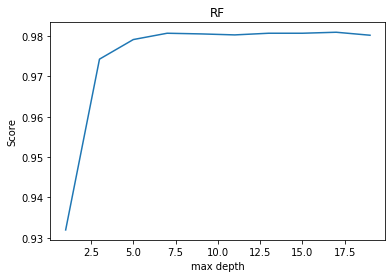

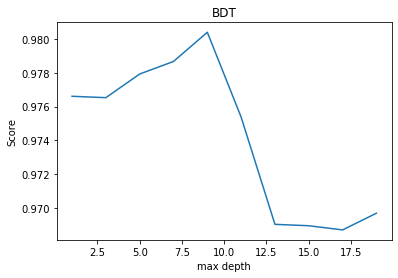

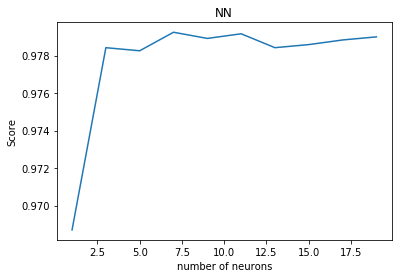

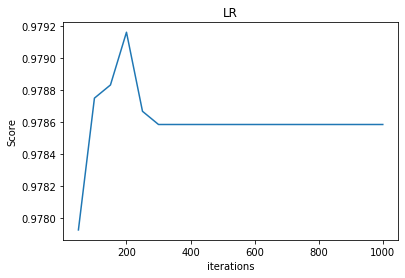

In [532]:
best_pars = {}
for alg in algs:
    ind = np.argmax(scores[alg])
    best_pars[alg] = scores[alg + '_pars'][ind]
    print('%s, %i, %.4f' % (alg, best_pars[alg], scores[alg][ind]))
    print(scores[alg+'_pars'])
    print(scores[alg])
    if 1:
        pyplot.figure()
        pyplot.plot(pars_dict[alg], scores[alg])
        pyplot.xlabel(pars_names[alg])
        pyplot.ylabel('Score')
        pyplot.title(alg)

# Add other classes to the basic ones

In [474]:
# using best RF
alg_choice = 'RF'
ind = 4
par_choice = scores[alg_choice + '_pars'][ind]
print(alg_choice, par_choice, scores[alg][ind])


clf_join = get_classifier(alg_choice, par_choice)
X = xdf[clf_mask]
y = ys[clf_mask]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.3, random_state=0)
clf_join.fit(X_train, y_train)


RF 9 0.9786655683690278


RandomForestClassifier(max_depth=9, max_features='sqrt', n_estimators=50)

In [475]:
all_classes = list(classes_df['Associated'])
pred = {}
for cl in all_classes:
    if cl not in classes_dict['UNAS']:
        cl_mask = (fgl_classes == cl)
        Xcl = xdf[cl_mask & ok_mask]
        pred[cl] = clf_join.predict_proba(Xcl).T


In [476]:
pred_mean = {}
for key, val in pred.items():
    pred_mean[key] = np.mean(pred[key], axis=1)

In [477]:
cl0, cl1 = clf_join.classes_
bias_0to1 = (1. * np.sum(y == cl0)) / (1. * np.sum(y == cl1))
print(bias_0to1)

12.856164383561644


In [478]:
classes_dict

{'PSR': ['psr', 'msp'],
 'AGN': ['bll', 'fsrq', 'agn', 'ssrq', 'bcu'],
 'UNAS': ['unk', 'unas']}

In [479]:
all_classes_dict = {key:[] for key in classes_dict.keys()}
all_classes_dict['UNAS'] = classes_dict['UNAS'].copy()
for key in pred_mean.keys():
    if pred_mean[key][0] > pred_mean[key][1] * bias_0to1:
        print('%s, %s, %.4f, %.4f' % (cl0, key, pred_mean[key][0], pred_mean[key][1]))
        all_classes_dict[cl0].append(key)
    else:
        print('%s, %s, %.4f, %.4f' % (cl1, key, pred_mean[key][0], pred_mean[key][1]))
        all_classes_dict[cl1].append(key)

PSR, gc, 0.1800, 0.8200
PSR, psr, 0.0957, 0.9043
PSR, msp, 0.1786, 0.8214
PSR, pwn, 0.5652, 0.4348
PSR, snr, 0.5125, 0.4875
PSR, spp, 0.6324, 0.3676
PSR, glc, 0.6177, 0.3823
PSR, sfr, 0.6047, 0.3953
PSR, hmb, 0.6097, 0.3903
PSR, lmb, 0.6790, 0.3210
PSR, bin, 0.3867, 0.6133
PSR, nov, 0.8659, 0.1341
AGN, bll, 0.9952, 0.0048
AGN, fsrq, 0.9903, 0.0097
AGN, rdg, 0.9694, 0.0306
AGN, agn, 0.9971, 0.0029
AGN, ssrq, 0.9899, 0.0101
AGN, css, 0.9934, 0.0066
AGN, bcu, 0.9823, 0.0177
AGN, nlsy1, 0.9758, 0.0242
AGN, sey, 0.9899, 0.0101
AGN, sbg, 0.9948, 0.0052
PSR, gal, 0.8333, 0.1667


In [480]:
dio3.savedict(all_classes_dict, all_classes_fn)

save dict to file:
../data_out/all_classes.yaml


# Classify all sources into two classes

In [516]:
ys_all = np.zeros(ns, dtype='<U6')
clf_mask_all = np.zeros(ns, dtype=bool)
for target_class, classes in all_classes_dict.items():
    for cl in classes:
        ys_all[fgl_classes == cl] = target_class
        if target_class != 'UNAS':
            clf_mask_all[fgl_classes == cl] = True
clf_mask_all &= ok_mask


In [517]:
X = xdf[clf_mask_all]
y = ys_all[clf_mask_all]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.3, random_state=0)
clf_2cl = RandomForestClassifier(max_depth=15, n_estimators=100, 
                                      max_features="sqrt")

clf_2cl.fit(X_train, y_train)


RandomForestClassifier(max_depth=15, max_features='sqrt')

In [518]:
all_classes = list(classes_df['Associated'])
pred_2class = {}
for cl in all_classes:
    if cl not in classes_dict['UNAS']:
        cl_mask = (fgl_classes == cl)
        Xcl = xdf[cl_mask & ok_mask]
        pred_2class[cl] = clf_2cl.predict_proba(Xcl).T


In [519]:
pred_mean_2class = {}
for key, val in pred.items():
    pred_mean_2class[key] = np.mean(pred_2class[key], axis=1)
pred_mean_2class

{'gc': array([0.06, 0.94]),
 'psr': array([0.0563, 0.9437]),
 'msp': array([0.1394, 0.8606]),
 'pwn': array([0.133, 0.867]),
 'snr': array([0.1942, 0.8058]),
 'spp': array([0.1796, 0.8204]),
 'glc': array([0.263, 0.737]),
 'sfr': array([0.362, 0.638]),
 'hmb': array([0.2645, 0.7355]),
 'lmb': array([0.2895, 0.7105]),
 'bin': array([0.1242, 0.8758]),
 'nov': array([0.5112, 0.4888]),
 'bll': array([0.9896, 0.0104]),
 'fsrq': array([0.9832, 0.0168]),
 'rdg': array([0.9747, 0.0253]),
 'agn': array([0.98, 0.02]),
 'ssrq': array([0.99, 0.01]),
 'css': array([0.986, 0.014]),
 'bcu': array([0.961, 0.039]),
 'nlsy1': array([0.9688, 0.0312]),
 'sey': array([0.9349, 0.0651]),
 'sbg': array([0.9908, 0.0092]),
 'gal': array([0.4631, 0.5369])}

# split into four classes

Subsplit the classes into two subclasses based on the confidence of two-class classification

In [520]:
cl0, cl1 = clf_join.classes_
bias_0to1 = (1. * np.sum(y == cl0)) / (1. * np.sum(y == cl1))
print(bias_0to1)

all_classes_dict_s2 = {}
for key in clf_join.classes_:
    all_classes_dict_s2[key + '0'] = []
    all_classes_dict_s2[key + '1'] = []

#thres = {}
#conf = 0.6
#for cl in clf_join.classes_:
#    thres[cl] = conf + ((1. - conf) * np.sum(y == cl)) / len(y)

high_conf_thres = {'AGN':0.97, 'PSR':0.8}

7.012844036697247


In [521]:
high_conf_thres

{'AGN': 0.97, 'PSR': 0.8}

In [522]:
for i, key in enumerate(clf_join.classes_):
    for cl in all_classes_dict[key]:
        if pred_mean[cl][i] > high_conf_thres[key]:
            akey = key + '0'
        else:
            akey = key + '1'
        print('%s, %s, %.4f' % (cl, akey, pred_mean[cl][i]))
        all_classes_dict_s2[akey].append(cl)


bll, AGN0, 0.9952
fsrq, AGN0, 0.9903
rdg, AGN1, 0.9694
agn, AGN0, 0.9971
ssrq, AGN0, 0.9899
css, AGN0, 0.9934
bcu, AGN0, 0.9823
nlsy1, AGN0, 0.9758
sey, AGN0, 0.9899
sbg, AGN0, 0.9948
gc, PSR0, 0.8200
psr, PSR0, 0.9043
msp, PSR0, 0.8214
pwn, PSR1, 0.4348
snr, PSR1, 0.4875
spp, PSR1, 0.3676
glc, PSR1, 0.3823
sfr, PSR1, 0.3953
hmb, PSR1, 0.3903
lmb, PSR1, 0.3210
bin, PSR1, 0.6133
nov, PSR1, 0.1341
gal, PSR1, 0.1667


In [523]:
all_classes_dict_s2

{'AGN0': ['bll', 'fsrq', 'agn', 'ssrq', 'css', 'bcu', 'nlsy1', 'sey', 'sbg'],
 'AGN1': ['rdg'],
 'PSR0': ['gc', 'psr', 'msp'],
 'PSR1': ['pwn',
  'snr',
  'spp',
  'glc',
  'sfr',
  'hmb',
  'lmb',
  'bin',
  'nov',
  'gal']}

# classify all sources into four classes

In [524]:
ys_s2 = np.zeros(ns, dtype='<U6')
#clf_mask_all = np.zeros(ns, dtype=bool)
for target_class, classes in all_classes_dict_s2.items():
    for cl in classes:
        ys_s2[fgl_classes == cl] = target_class
        #if target_class != 'UNAS':
        #    clf_mask_all[fgl_classes == cl] = True
#clf_mask_all &= ok_mask


In [525]:
X = xdf[clf_mask_all]
y = ys_s2[clf_mask_all]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.3, random_state=0)
#clf_s2 = get_classifier(alg_choice, par_choice)
clf_s2 = RandomForestClassifier(max_depth=15, n_estimators=100, 
                                      max_features="sqrt")
clf_s2.fit(X_train, y_train)


RandomForestClassifier(max_depth=15, max_features='sqrt')

In [526]:
pred_s2 = {}
for cl in all_classes:
    if cl not in classes_dict['UNAS']:
        cl_mask = (fgl_classes == cl)
        Xcl = xdf[cl_mask & ok_mask]
        pred_s2[cl] = clf_s2.predict_proba(Xcl).T


In [527]:
clf_s2.classes_

array(['AGN0', 'AGN1', 'PSR0', 'PSR1'], dtype='<U6')

In [528]:
pred_mean_s2 = {}
for key, val in pred_s2.items():
    pred_mean_s2[key] = np.mean(pred_s2[key], axis=1)
pred_mean_s2

{'gc': array([0.07, 0.  , 0.13, 0.8 ]),
 'psr': array([0.0525, 0.0024, 0.8063, 0.1388]),
 'msp': array([0.1376, 0.002 , 0.7778, 0.0826]),
 'pwn': array([0.1293, 0.0125, 0.056 , 0.8022]),
 'snr': array([0.1885, 0.0148, 0.1251, 0.6717]),
 'spp': array([0.1779, 0.0051, 0.0786, 0.7384]),
 'glc': array([0.276 , 0.0081, 0.153 , 0.563 ]),
 'sfr': array([0.2511, 0.04  , 0.11  , 0.5989]),
 'hmb': array([0.2211, 0.0128, 0.1227, 0.6434]),
 'lmb': array([0.2783, 0.0083, 0.1259, 0.5874]),
 'bin': array([0.1105, 0.0037, 0.3443, 0.5415]),
 'nov': array([0.5179, 0.0055, 0.0931, 0.3835]),
 'bll': array([0.98  , 0.0088, 0.0041, 0.0071]),
 'fsrq': array([0.9769, 0.0064, 0.0067, 0.0101]),
 'rdg': array([0.5255, 0.4459, 0.0072, 0.0214]),
 'agn': array([0.9754, 0.0054, 0.0059, 0.0133]),
 'ssrq': array([0.9626, 0.0011, 0.0154, 0.0209]),
 'css': array([9.7974e-01, 5.4183e-04, 1.3581e-02, 6.1395e-03]),
 'bcu': array([0.9537, 0.0072, 0.0124, 0.0267]),
 'nlsy1': array([0.9723, 0.0113, 0.0063, 0.0101]),
 'sey': a

In [529]:

two_class_inds = {}
four_class_inds = {}
for i, cl in enumerate(clf_join.classes_):
    two_class_inds[cl] = [i]
    four_class_inds[cl] = [k for k in range(len(clf_s2.classes_)) if clf_s2.classes_[k].startswith(cl)]


In [531]:
print('class  p_av_2  p_av_4, p2cl/p4cl')
for cl in all_classes_dict.keys():
    if cl == 'UNAS':
        continue
    print(cl)
    for key in all_classes_dict[cl]:
        prob_2cl = np.sum(pred_mean_2class[key][two_class_inds[cl]])
        prob_4cl = np.sum(pred_mean_s2[key][four_class_inds[cl]])
        ratio = prob_2cl / prob_4cl
        print('%s, %.3f, %.3f,  %.3f' % ( key, prob_2cl, prob_4cl, ratio))


class  p_av_2  p_av_4, p2cl/p4cl
PSR
gc, 0.940, 0.930,  1.011
psr, 0.944, 0.945,  0.998
msp, 0.861, 0.860,  1.000
pwn, 0.867, 0.858,  1.010
snr, 0.806, 0.797,  1.011
spp, 0.820, 0.817,  1.004
glc, 0.737, 0.716,  1.029
sfr, 0.638, 0.709,  0.900
hmb, 0.735, 0.766,  0.960
lmb, 0.710, 0.713,  0.996
bin, 0.876, 0.886,  0.989
nov, 0.489, 0.477,  1.025
gal, 0.537, 0.540,  0.995
AGN
bll, 0.990, 0.989,  1.001
fsrq, 0.983, 0.983,  1.000
rdg, 0.975, 0.971,  1.003
agn, 0.980, 0.981,  0.999
ssrq, 0.990, 0.964,  1.027
css, 0.986, 0.980,  1.006
bcu, 0.961, 0.961,  1.000
nlsy1, 0.969, 0.984,  0.985
sey, 0.935, 0.918,  1.018
sbg, 0.991, 0.987,  1.004


In [3]:
import numpy as np
(1. - np.exp(-1))**(1.5)

0.502573833210253